# EDA na Prática — Online Food Delivery Dataset

Atividade: EDA na Prática (aulas 9, 10 e 11)

Aluno: Caio Leimig Rodrigues da Silva

Dataset: [Online Food Ordering Dataset (Kaggle)](https://www.kaggle.com/datasets/srisyra02/online-food-ordering-dataset)

Estrutura seguindo a demonstração da Aula 11 (dataset Heart Disease), replicada aqui no dataset escolhido.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import entropy

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

palette_classe = {"No": COR_CONTEXTO, "Yes": COR_DESTAQUE}

## Carregando o Dataset

In [ ]:
# Online Food Ordering Dataset (Kaggle)
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("online food delivery dataset.csv")
df.head()

Saving online food delivery dataset.csv to online food delivery dataset (1).csv


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicatas.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(388, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 388 entries, 0 to 387
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         388 non-null    int64  
 1   Gender                      388 non-null    object 
 2   Marital Status              388 non-null    object 
 3   Occupation                  388 non-null    object 
 4   Monthly Income              388 non-null    object 
 5   Educational Qualifications  388 non-null    object 
 6   Family size                 388 non-null    int64  
 7   Customer Type               388 non-null    object 
 8   latitude                    388 non-null    float64
 9   longitude                   388 non-null    float64
 10  Pin code                    388 non-null    int64  
 11  Output                      388 non-null    object 
 12  Feedback                    388 non-null    object 
 13  Unnamed: 13                 388 non

In [ ]:
df.describe()

,Age,Family size,latitude,longitude,Pin code
count,388.000000,388.000000,388.000000,388.000000,388.000000
mean,24.628866,3.280928,12.972058,77.600160,560040.113402
std,2.975593,1.351025,0.044489,0.051354,31.399609
min,18.000000,1.000000,12.865200,77.484200,560001.000000
25%,23.000000,2.000000,12.936900,77.565275,560010.750000
50%,24.000000,3.000000,12.977000,77.592100,560033.500000
75%,26.000000,4.000000,12.997025,77.630900,560068.000000
max,33.000000,6.000000,13.102000,77.758200,560109.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(103)

**Coluna redundante**

A coluna `Unnamed: 13` (a última do CSV) chama atenção — vamos checar se ela carrega informação nova ou se é só uma cópia de outra coluna.

In [ ]:
pd.crosstab(df["Unnamed: 13"], df["Output"])

Output,No,Yes
Unnamed: 13,,
No,87,0
Yes,0,301


**Pra discutir:** `Unnamed: 13` bate 1-para-1 com `Output` (nunca discorda)? Se sim, ela não carrega nenhuma informação adicional — é candidata a descarte, igual fizemos com `num` no dataset de referência (lá a transformação foi simplificar, aqui é remover redundância pura).

*Resposta*: Sim, bate 1-para-1 (todo Yes→Yes, todo No→No, sem exceção). Não carrega informação nova; confirma que é candidata segura a descarte.

**Sobre a variável-alvo**

Diferente do Heart Disease (onde `num` precisou ser simplificado em uma classe binária), aqui `Output` já vem binário (`Yes`/`No`). Vamos usá-lo como referência de classe ao longo da análise, do mesmo jeito que `doenca_cardiaca` foi usado na demonstração.

In [ ]:
df["Output"].value_counts()

,count
Output,
Yes,301
No,87


## 2. Dados Ausentes e Duplicados

In [ ]:
df.isna().sum()

,0
Age,0
Gender,0
Marital Status,0
Occupation,0
Monthly Income,0
Educational Qualifications,0
Family size,0
Customer Type,0
latitude,0
longitude,0


**Discussão:** alguma feature tem dados ausentes no formato tradicional (`NaN`)?

*Resposta*: Não. Rodando df.isna().sum() no dataset, nenhuma das 14 colunas apresenta valor NaN

**Conhecimento de domínio**

Diferente do Heart Disease (que tinha `ca` e `thal` com ausentes reais), este dataset não apresenta `NaN` explícitos. Mas isso não quer dizer que os dados estão limpos: encontramos na Seção 1 uma coluna redundante (`Unnamed: 13`) e 103 linhas totalmente duplicadas — o equivalente aqui a um problema de qualidade que precisa ser tratado antes da análise, mesmo sem ausência tradicional.

Vamos também checar se existe alguma sujeira de formatação escondida nas colunas categóricas (espaços, capitalização inconsistente), que funciona como uma forma de "ausência disfarçada" de padronização.

In [ ]:
for col in df.select_dtypes(include="object").columns:
    valores = df[col].unique()
    sujos = [v for v in valores if isinstance(v, str) and v != v.strip()]
    if sujos:
        print(f"{col}: valores com espaço extra -> {sujos}")

Feedback: valores com espaço extra -> ['Negative ']


**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver ausentes reais, vale a pena repetir aqui a checagem de coocorrência entre colunas ausentes feita na demonstração (`pd.crosstab` entre indicadores `.isna()`), pra distinguir um padrão sistemático (MAR/MNAR) de eventos independentes (MCAR). Nesse dataset especificamente isso não se aplica, já que não há `NaN`.

## 3. Princípio Distribucional

Ainda com os dados originais (sem remover duplicatas/coluna redundante), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai orientar as decisões de tratamento na Seção 4.

In [ ]:
VARS_QUANT = ["Age", "Family size"]
VARS_QUALI = ["Gender", "Marital Status", "Occupation", "Monthly Income",
              "Educational Qualifications", "Customer Type", "Feedback"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,24.63,24.00,2.98,18.00,33.00,0.81,0.26
Family size,3.28,3.00,1.35,1.00,6.00,0.40,-0.66


**Pra discutir:** só temos duas variáveis realmente quantitativas aqui (`Age` e `Family size` — `latitude`/`longitude` são coordenadas, não quantidades comparáveis, e `Pin code` é um identificador). `Age` tem assimetria em torno de 0.8 (moderada à direita) e curtose baixa; `Family size` tem assimetria mais leve. Isso é coerente com o que vocês esperariam de um público majoritariamente jovem/estudante?

*Resposta*: Sim, é coerente. Age com skew ≈0,81 (assimetria moderada à direita) faz sentido porque o público está concentrado numa faixa jovem estreita (18-27 anos majoritariamente), com uma cauda mais longa de poucas pessoas mais velhas (até 33) puxando a distribuição pra direita.

### Distribuições de dados

Onde fizer sentido, comparamos `Output = No` (rosa) vs. `Output = Yes` (roxo) — mesma convenção de cor da demonstração.

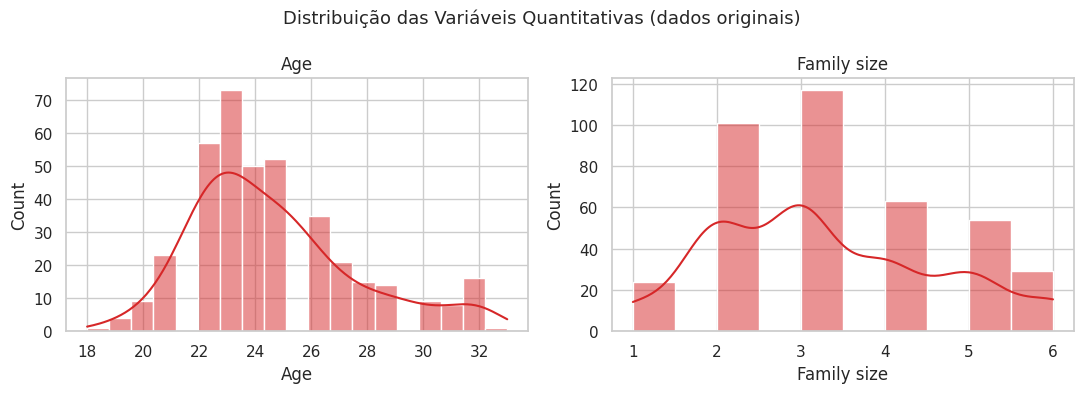

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_ALERTA, ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas (dados originais)", fontsize=13)
plt.tight_layout()
plt.show()

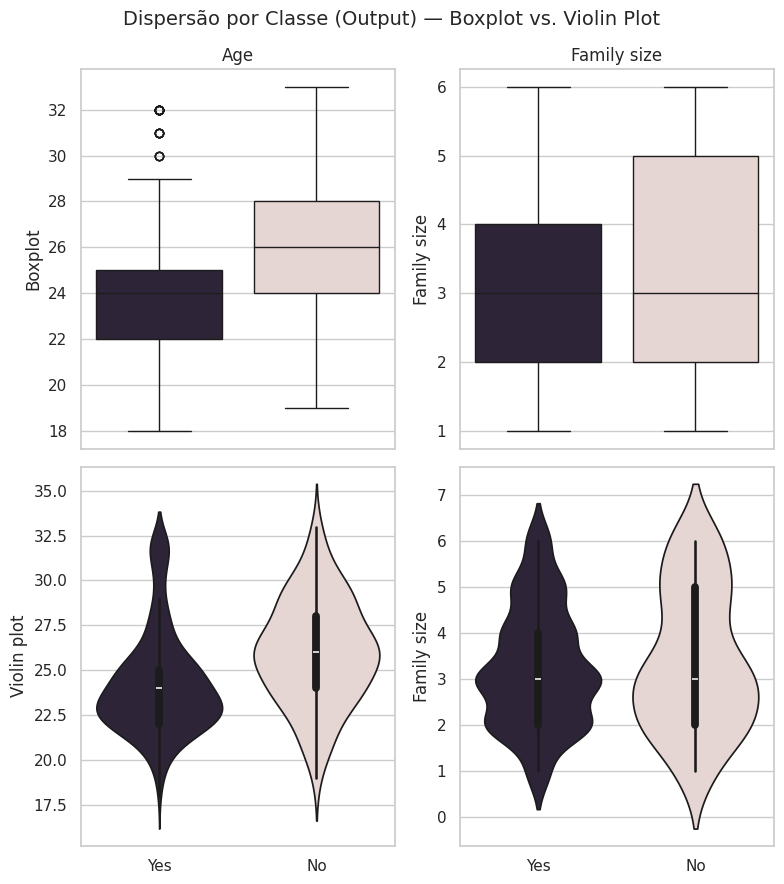

In [ ]:
fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="Output", y=col, hue="Output",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="Output", y=col, hue="Output",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe (Output) — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente diferente entre `No` e `Yes`? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ter relação com o desfecho.

*Resposta*: Sim, Age mostra diferença: a caixa (IQR) de quem respondeu Yes fica deslocada pra baixo em relação à de No — idade média de 24,3 anos entre os Yes contra 25,9 anos entre os No.

#### Testes de Aderência

*Será que `Age` e `Family size` seguem uma distribuição normal?* Usamos o **Shapiro-Wilk** como teste de aderência, junto com o **QQ-Plot** como visualização de apoio.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": p, "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Age,0.9328,3.284309e-12,True
Family size,0.9177,9.834827e-14,True


**Como ler:** se os pontos seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam nas pontas indicam cauda mais pesada/leve que a normal.

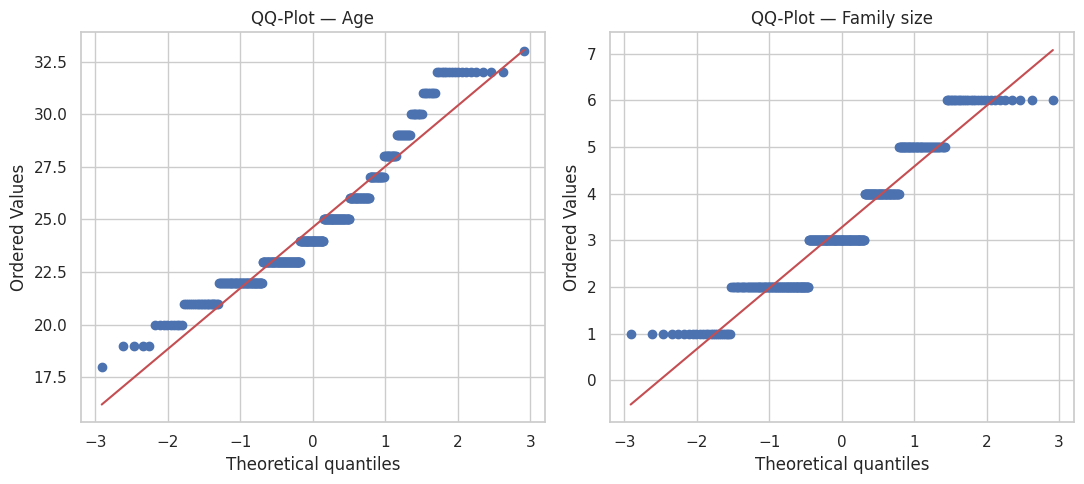

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col in zip(axes, VARS_QUANT):
    stats.probplot(df[col].dropna(), dist="norm", plot=ax)
    ax.set_title(f"QQ-Plot — {col}")
plt.tight_layout()
plt.show()

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a proporção acumulada de observações até ali.

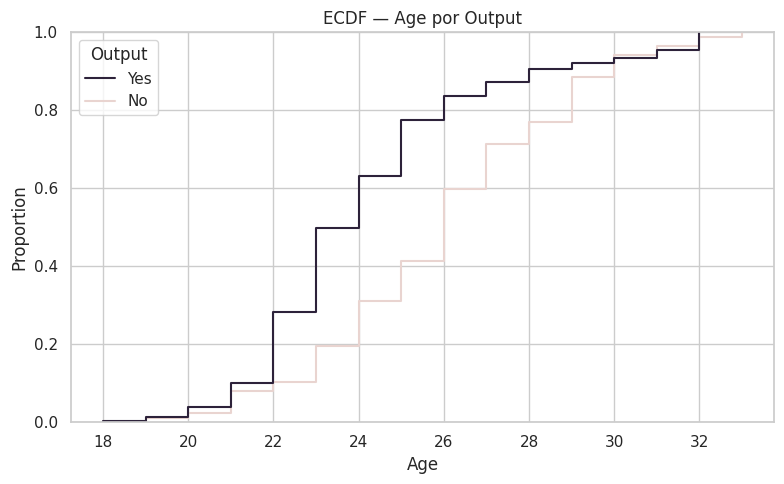

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Age", hue="Output",
             palette=palette_classe)
plt.title("ECDF — Age por Output")
plt.tight_layout()
plt.show()

**Pra discutir:** em algum trecho do eixo X as duas curvas se distanciam mais? Ali está a faixa etária que mais diferencia quem respondeu `Yes` de quem respondeu `No`.

*Resposta*: Sim — o maior afastamento entre as curvas acontece por volta dos 23 a 26 anos, com o pico em torno dos 25 anos (gap máximo ≈0,34 na proporção acumulada).

### Métricas de Tendência Central

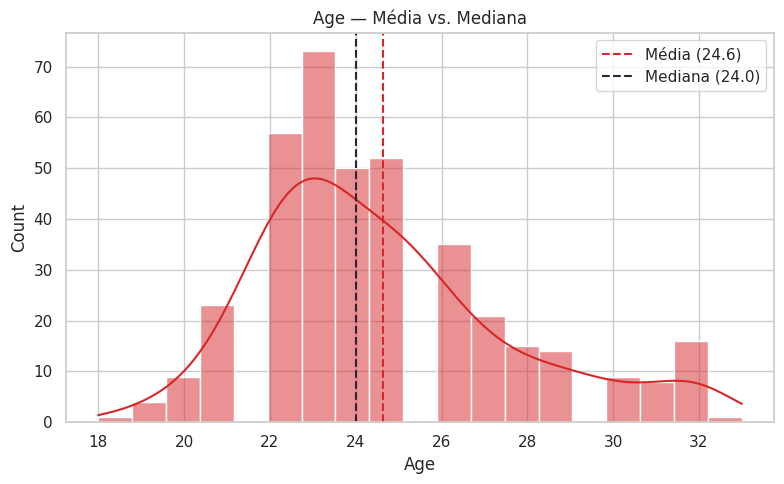

In [ ]:
media_age = df["Age"].mean()
mediana_age = df["Age"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", kde=True, color=COR_ALERTA)
plt.axvline(media_age, color=COR_ALERTA, linestyle="--", label=f"Média ({media_age:.1f})")
plt.axvline(mediana_age, color=COR_DESTAQUE, linestyle="--", label=f"Mediana ({mediana_age:.1f})")
plt.title("Age — Média vs. Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
Age,8.85,2.98,3.0
Family size,1.83,1.35,2.0


## 4. Tratamento de Dados Ausentes/Duplicados e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os problemas de qualidade encontrados (`Unnamed: 13`, duplicatas) quanto os outliers.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Age,18.5,30.5,26.0
Family size,-1.0,7.0,0.0


### Visualizando os Outliers

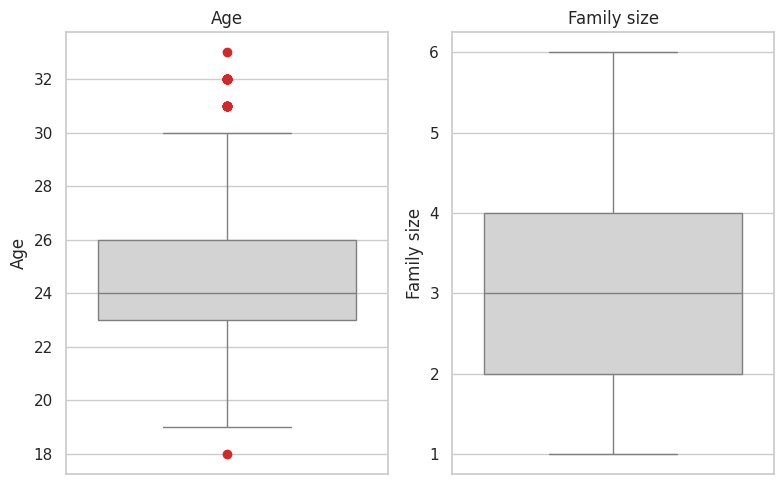

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, markersize=6),
                ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

**Pra discutir:** o slide da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Impossível/erro | Corrigir ou remover |
| Contextual | Depende do recorte | Investigar antes de decidir |

Os "outliers" de `Age` (>30 anos aproximadamente) são, pela regra do IQR, estatisticamente atípicos — mas fazem sentido no mundo real (pessoas de 30+ que pedem comida por app não são impossíveis). Isso sugere que são outliers **estatísticos legítimos**, não erros de domínio. Vocês concordam?

*Resposta*: Concordo. Os limites do IQR marcam qualquer Age acima de 30,5 anos como outlier, e são 26 observações nessa condição — mas o valor máximo é 33 anos, uma idade perfeitamente plausível para alguém que pede comida por aplicativo.

### Decidindo o Tratamento dos Dados Ausentes/Duplicados

Reunindo o que já discutimos: `Unnamed: 13` não carrega nenhuma informação além do que já está em `Output`, e as 103 linhas duplicadas inflam artificialmente as frequências sem adicionar informação nova. Com esses achados, decidimos:
- Remover as linhas totalmente duplicadas
- Descartar a coluna `Unnamed: 13`
- Padronizar espaços em branco nas colunas de texto (ex.: `'Negative '` -> `'Negative'`)

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df = df.drop_duplicates().drop(columns=["Unnamed: 13"]).reset_index(drop=True)
str_cols = df.select_dtypes(include="object").columns
df[str_cols] = df[str_cols].apply(lambda s: s.str.strip())

linhas_depois = df.shape[0]
print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 388 | Linhas depois: 285 | Removidas: 103


### Decidindo o Tratamento dos Outliers

Assim como no dataset de referência, aqui **também não vamos remover automaticamente** os outliers de `Age`. Pelos valores encontrados (dentro de uma faixa etária plausível, ainda que na cauda), a classificação é de outlier estatístico legítimo — remover perderia informação real sobre uma parte do público. Optamos por manter os dados como estão e seguir para a próxima etapa.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos as duplicatas/coluna redundante e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o retrato "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,24.68,24.00,3.04,18.00,33.00,0.74,0.19
Family size,3.27,3.00,1.36,1.00,6.00,0.44,-0.63


### Comparando "antes" x "depois"

In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois
Age,0.810,0.743,0.256,0.189
Family size,0.401,0.437,-0.663,-0.628


**Pra discutir:** os valores mudaram muito? Removemos ~27% das linhas (as duplicadas), bem mais do que os ~2% removidos no dataset de referência — mesmo assim, a forma da distribuição (skewness/kurtosis) muda pouco? Isso é esperado quando as linhas duplicadas eram uma amostra proporcional do dataset original, e não um subgrupo enviesado.

*Resposta*: Não, mudaram pouco. Age: skewness caiu de 0,81 para 0,74 e kurtosis de 0,26 para 0,19. Family size: skewness subiu de 0,40 para 0,44 e kurtosis foi de -0,66 para -0,63. São variações pequenas, na segunda casa decimal na maioria dos casos.

**As variáveis ainda rejeitam normalidade?** Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
for col in VARS_QUANT:
    stat_antes, p_antes = stats.shapiro(df_antes[col].dropna())
    stat_depois, p_depois = stats.shapiro(df[col].dropna())
    print(f"{col} — Shapiro-Wilk (antes):  estatística={stat_antes:.4f}, p-valor={p_antes:.4g}")
    print(f"{col} — Shapiro-Wilk (depois): estatística={stat_depois:.4f}, p-valor={p_depois:.4g}\n")

Age — Shapiro-Wilk (antes):  estatística=0.9328, p-valor=3.284e-12
Age — Shapiro-Wilk (depois): estatística=0.9410, p-valor=2.899e-09

Family size — Shapiro-Wilk (antes):  estatística=0.9177, p-valor=9.835e-14
Family size — Shapiro-Wilk (depois): estatística=0.9148, p-valor=1.179e-11



**Visualizando antes x depois, lado a lado**

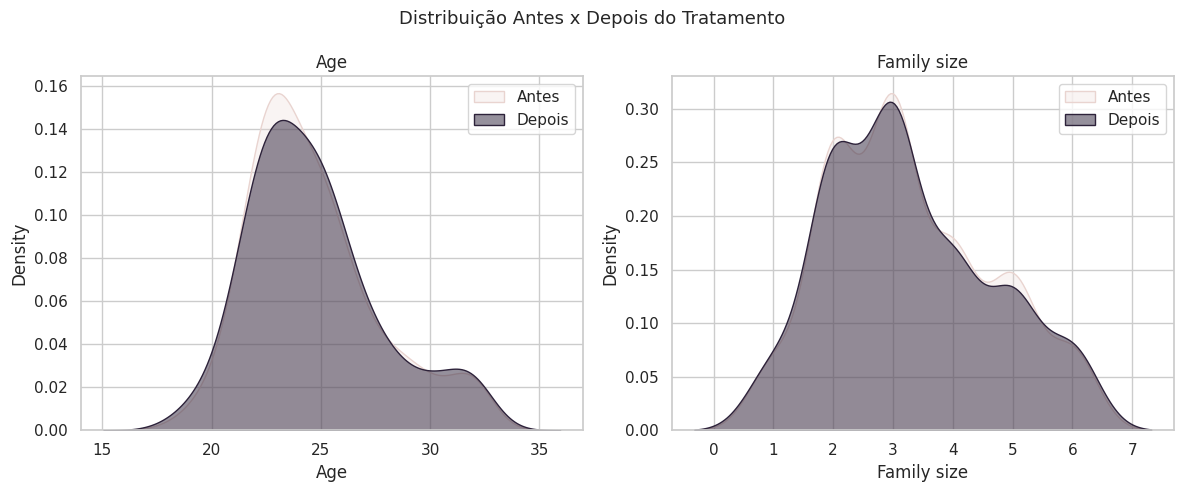

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, VARS_QUANT):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax, alpha=0.5)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=13)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso reforça a leitura de que as duplicatas eram uma cópia proporcional do dataset, e não um viés escondido.

*Resposta*: Sim, as curvas de densidade (KDE) de Age e Family size praticamente se sobrepõem entre "antes" e "depois" do tratamento.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.

#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- Gender ---
        absoluta  relativa
Gender                    
Male         164     0.575
Female       121     0.425

--- Marital Status ---
                   absoluta  relativa
Marital Status                       
Single                  189     0.663
Married                  87     0.305
Prefer not to say         9     0.032

--- Occupation ---
                absoluta  relativa
Occupation                        
Student              144     0.505
Employee              94     0.330
Self Employeed        38     0.133
House wife             9     0.032

--- Monthly Income ---
                 absoluta  relativa
Monthly Income                     
No Income             131     0.460
25001 to 50000         52     0.182
More than 50000        47     0.165
10001 to 25000         36     0.126
Below Rs.10000         19     0.067

--- Educational Qualifications ---
                            absoluta  relativa
Educational Qualifications                    
Graduate                  

#### Visualizando as frequências

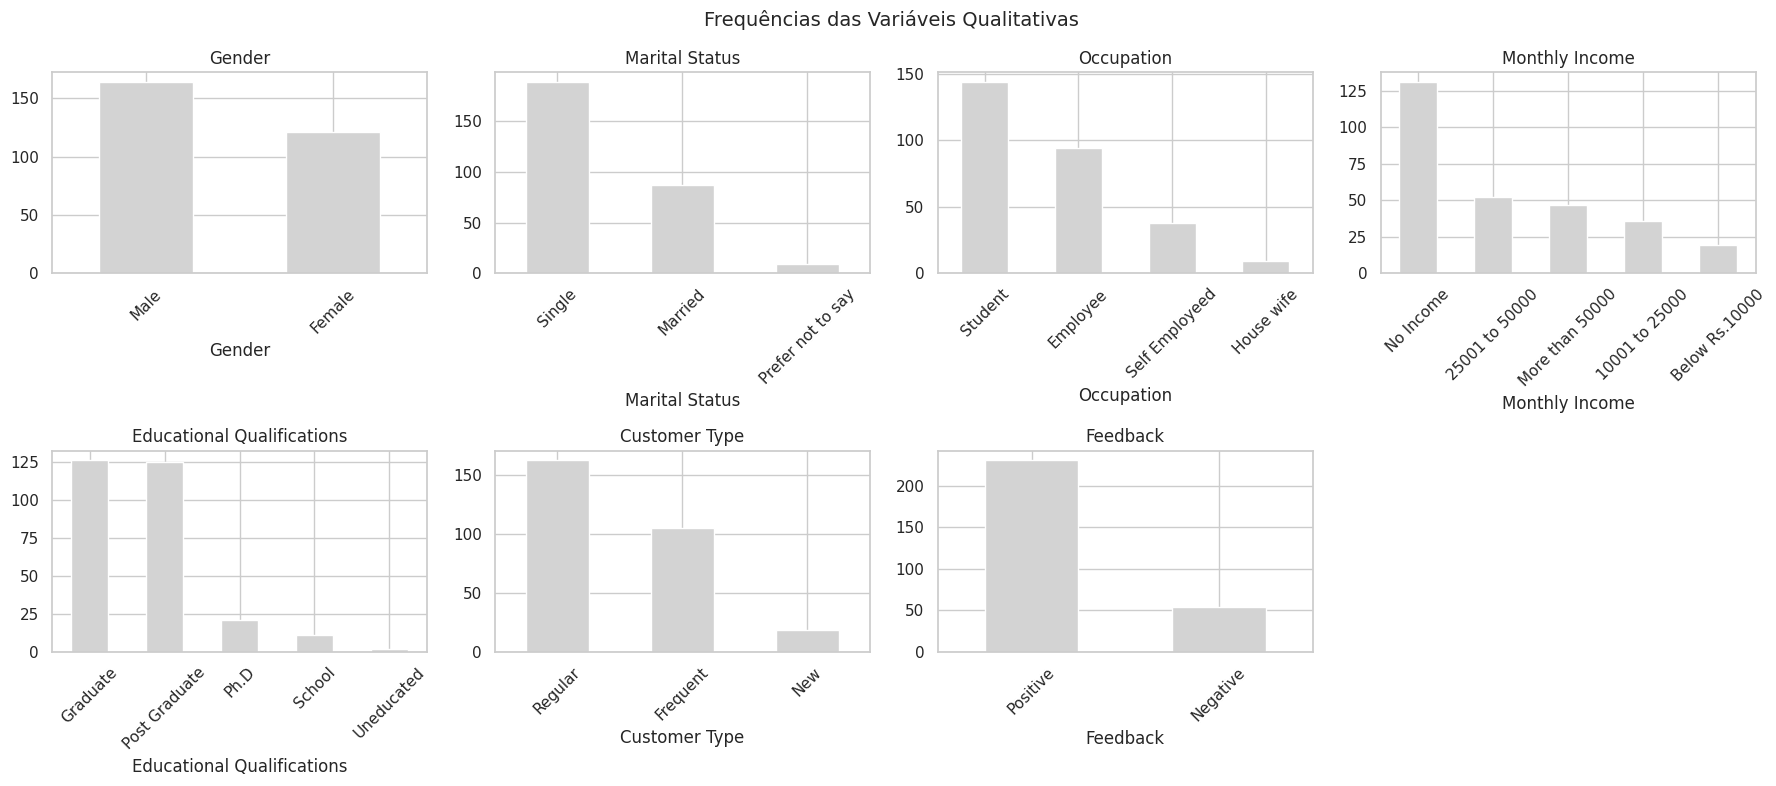

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

axes[-1].axis("off")
fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais pra frente.

*Resposta*: Sim, várias aparecem desbalanceadas nos gráficos de frequência: Ocupation, Monthly Income, Educational Qualifications, Marital Status

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, perto de 0 = uma classe domina.

In [ ]:
def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["Output"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Gender,2.0,1.36,0.984
Marital Status,3.0,21.00,0.677
Occupation,4.0,16.00,0.785
Monthly Income,5.0,6.89,0.874
Educational Qualifications,5.0,63.00,0.668
Customer Type,3.0,9.00,0.786
Feedback,2.0,4.28,0.700
Output,2.0,3.19,0.793


**Pra discutir:** `Educational Qualifications` e `Marital Status` aparecem com razão de desbalanceamento bem alta — vale olhar quantas observações sobram nas categorias minoritárias (`Uneducated`, `Prefer not to say`) antes de tirar conclusões sobre elas. E o próprio alvo `Output` — está balanceado o suficiente pra não distorcer a análise bivariada?

*Resposta*: Olhando as contagens absolutas:
Educational Qualifications: razão de desbalanceamento 63 — Uneducated tem apenas 2 observações contra 126 de Graduate e 125 de Post Graduate.
Marital Status: razão 21 — Prefer not to say tem 9 observações contra 189 de Single e 87 de Married.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo `Output`.

#### Quantitativa x Quantitativa — Correlação

Como só temos duas variáveis realmente quantitativas, o painel de correlação é simples — mas ainda vale comparar Pearson (linear), Spearman e Kendall (monotônicas, mais robustas a outliers).

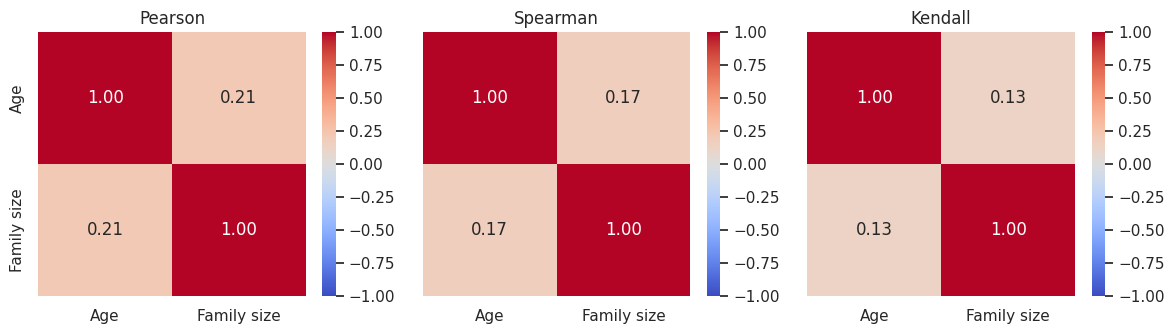

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Kendall")
plt.tight_layout()
plt.show()

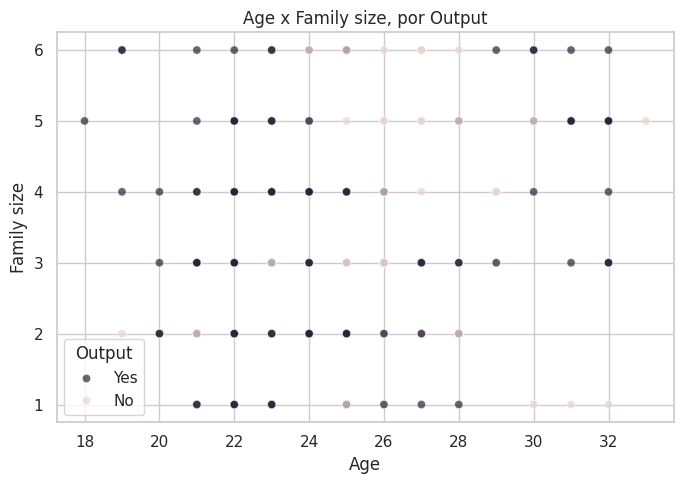

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Age", y="Family size", hue="Output",
                palette=palette_classe, alpha=0.7)
plt.title("Age x Family size, por Output")
plt.tight_layout()
plt.show()

**Pra discutir:** existe alguma relação visível entre idade e tamanho da família aqui? Faz sentido esperar pouca correlação entre essas duas variáveis nesse público (majoritariamente jovem/estudante)?

*Resposta*: Visualmente não — o scatter de Age x Family size mostra uma nuvem de pontos espalhada, sem uma tendência clara de crescimento ou queda. Isso bate com os números calculados antes: r≈0,21 (Pearson), 0,17 (Spearman) e 0,13 (Kendall) — todos na faixa de correlação fraca (|r| < 0,3).

#### Quantitativa x Qualitativa — Comparando Grupos

Usamos **T-test** (Welch, paramétrico) e **Mann-Whitney** (não-paramétrico) pra comparar `Age` entre `Output = Yes` e `Output = No` — já sabemos da Seção 3 que `Age` não segue uma normal, então o Mann-Whitney é o resultado mais confiável.

In [ ]:
grupo_yes = df.loc[df["Output"] == "Yes", "Age"]
grupo_no = df.loc[df["Output"] == "No", "Age"]

stat_t, p_t = stats.ttest_ind(grupo_yes, grupo_no, equal_var=False)
stat_u, p_u = stats.mannwhitneyu(grupo_yes, grupo_no)

print(f"Idade média — Output=Yes: {grupo_yes.mean():.1f} | Output=No: {grupo_no.mean():.1f}")
print(f"T-test          — p-valor={p_t:.5g}")
print(f"Mann-Whitney     — p-valor={p_u:.5g}")
print("Concordam (ambos < 0.05)?", (p_t < 0.05) == (p_u < 0.05))

Idade média — Output=Yes: 24.3 | Output=No: 25.9
T-test          — p-valor=0.00017423
Mann-Whitney     — p-valor=8.4241e-06
Concordam (ambos < 0.05)? True


**Pra discutir:** os dois testes concordam? A diferença de idade entre quem respondeu `Yes` e `No` é estatisticamente significativa — isso é grande o suficiente pra ter relevância prática, ou é só um efeito de amostra grande?

*Resposta*: Sim, os dois testes concordam (T-test p≈0,00017, Mann-Whitney p≈0,00001 — ambos < 0,05). É estatisticamente significativo, mas a diferença prática é pequena (1,6 ano, 24,3 vs 25,9 anos).

ANOVA          — Family size entre Customer Type: estatística=574.684, p-valor=3.3435e-100
Kruskal-Wallis — Family size entre Customer Type: estatística=229.883, p-valor=1.2066e-50


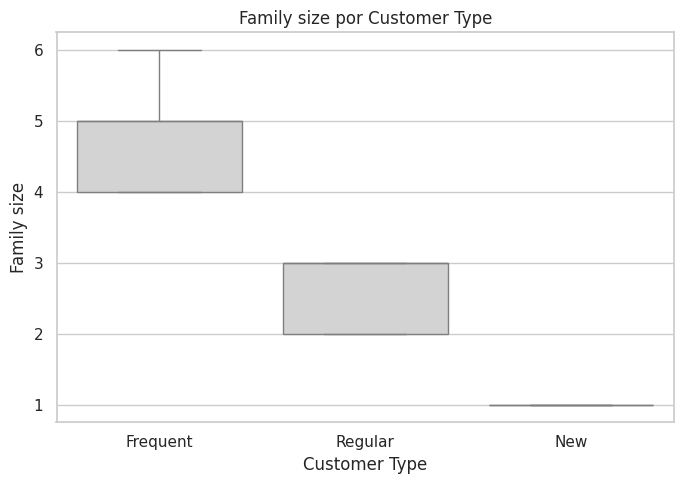

In [ ]:
grupos_ct = [grupo["Family size"].values for _, grupo in df.groupby("Customer Type")]

stat_anova, p_anova = stats.f_oneway(*grupos_ct)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_ct)          # não-paramétrico

print(f"ANOVA          — Family size entre Customer Type: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — Family size entre Customer Type: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Customer Type", y="Family size", color=COR_NEUTRA)
plt.title("Family size por Customer Type")
plt.tight_layout()
plt.show()

**Pra discutir:** repare que todo cliente `New` tem `Family size = 1`, sem nenhuma variação — isso é um padrão real de comportamento (quem mora sozinho testa mais apps novos?), ou parece um artefato de como o dataset foi construído/rotulado? Como isso deveria ser tratado num relatório?

*Resposta*: Os 18 clientes classificados como New têm Family size = 1 em todos os casos, sem uma única exceção — variância zero.

#### Qualitativa x Qualitativa

Testamos associação entre pares de categóricas com o **Qui-Quadrado**.

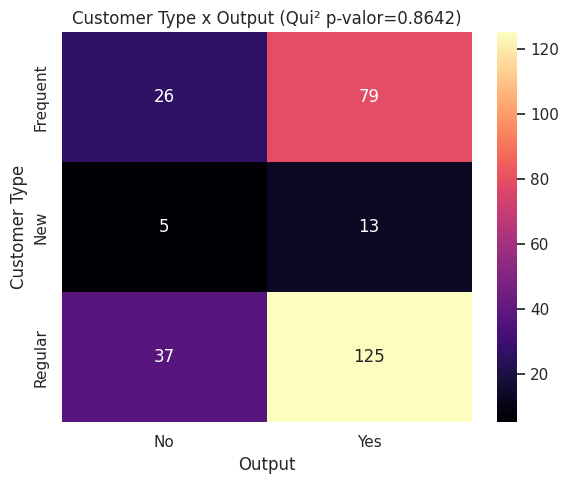

In [ ]:
contingencia_ct = pd.crosstab(df["Customer Type"], df["Output"])
chi2_ct, p_ct, gl_ct, esperado_ct = stats.chi2_contingency(contingencia_ct)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_ct, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Customer Type x Output (Qui² p-valor={p_ct:.4g})")
plt.tight_layout()
plt.show()

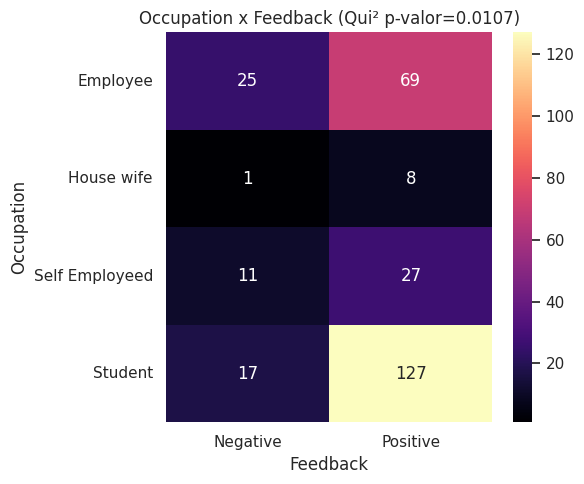

In [ ]:
contingencia_of = pd.crosstab(df["Occupation"], df["Feedback"])
chi2_of, p_of, gl_of, esperado_of = stats.chi2_contingency(contingencia_of)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_of, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Occupation x Feedback (Qui² p-valor={p_of:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** `Customer Type` parece independente de `Output`, mas `Occupation` parece associado a `Feedback`. Faz sentido que o tipo de cliente (novo/regular/frequente) não determine sozinho se ele vai responder `Yes`, enquanto a ocupação (estudante, empregado etc.) tenha relação com a satisfação relatada?

*Resposta*: Os números confirmam essa leitura: Customer Type x Output tem p=0,864 no Qui-Quadrado (nada significativo — não há evidência de associação), enquanto Occupation x Feedback tem p=0,011 (significativo).

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** é: será que a proporção de `Output = Yes` muda de forma desigual entre subgrupos demográficos (gênero, faixa etária)?

In [ ]:
df["faixa_etaria"] = pd.cut(df["Age"], bins=[17, 21, 24, 27, 35],
                              labels=["18-21", "22-24", "25-27", "28+"])

print("Desbalanceamento — Gender:")
print(metrica_desbalanceamento(df["Gender"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — Gender:
n_classes                 2.000
razao_desbalanceamento    1.360
entropia_normalizada      0.984
dtype: float64

Desbalanceamento — faixa etária:
n_classes                 4.000
razao_desbalanceamento    4.130
entropia_normalizada      0.906
dtype: float64


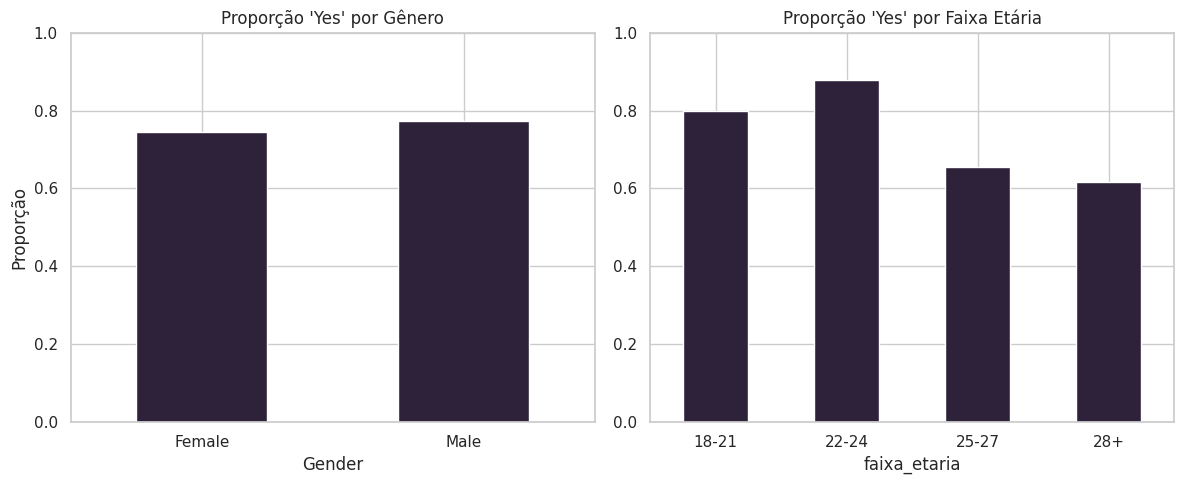

In [ ]:
prop_por_genero = pd.crosstab(df["Gender"], df["Output"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["Output"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_genero["Yes"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Yes' por Gênero")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Yes"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Yes' por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

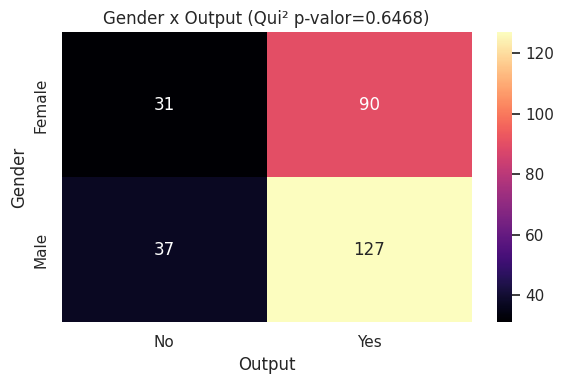

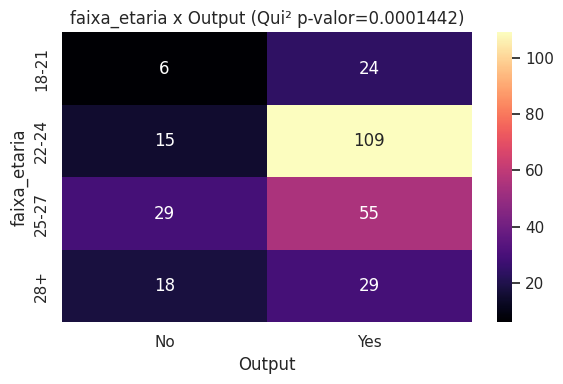

In [ ]:
for atributo in ["Gender", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["Output"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x Output (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre gênero e `Output`? E entre faixa etária e `Output`? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não implica causalidade — pode haver variáveis de confusão (ex.: ocupação, renda) por trás da relação idade-resposta.

*Resposta*: Não pra gênero, sim pra faixa etária. Gender x Output: p=0,647 — sem evidência de associação (proporção de Yes é 74,4% entre mulheres e 77,4% entre homens, uma diferença pequena e estatisticamente compatível com acaso). faixa_etaria x Output: p=0,00014 — associação estatisticamente significativa (Yes cai de ~80-88% nos grupos de 18-24 anos para ~62-66% nos grupos de 25+).

#### Outliers bivariados

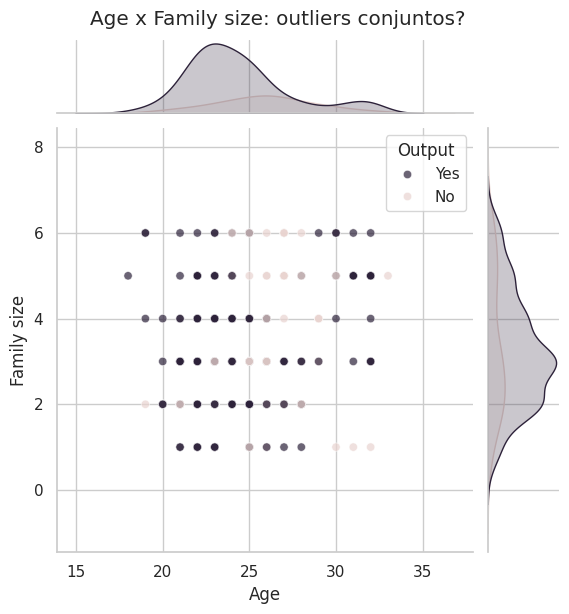

In [ ]:
sns.jointplot(data=df, x="Age", y="Family size", hue="Output",
              palette=palette_classe, alpha=0.7, height=6)
plt.suptitle("Age x Family size: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `Age` e `Family size`?

*Resposta*: Sim. Os casos mais extremos por distância de Mahalanobis (que mede o quão incomum é uma combinação de duas variáveis, considerando a correlação entre elas) são:

### Análise Multivariada

#### Matriz de Correlação

Incluímos `latitude`/`longitude` aqui só pra enriquecer a matriz — lembrando que elas são coordenadas geográficas (concentradas em Bangalore), não quantidades no sentido estatístico tradicional.

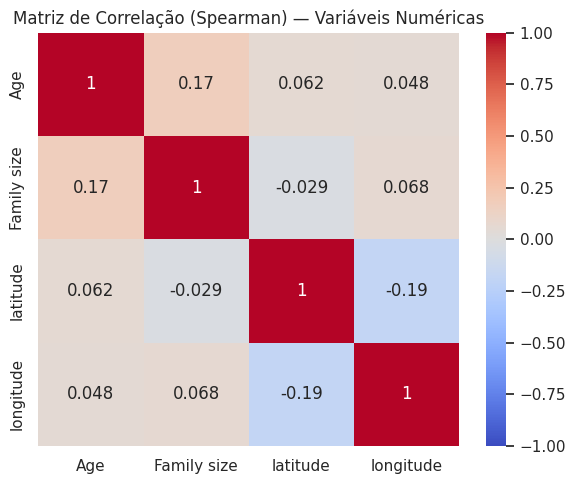

In [ ]:
VARS_MULTI = ["Age", "Family size", "latitude", "longitude"]

plt.figure(figsize=(6, 5))
sns.heatmap(df[VARS_MULTI].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Numéricas")
plt.tight_layout()
plt.show()

#### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão x Correlação')

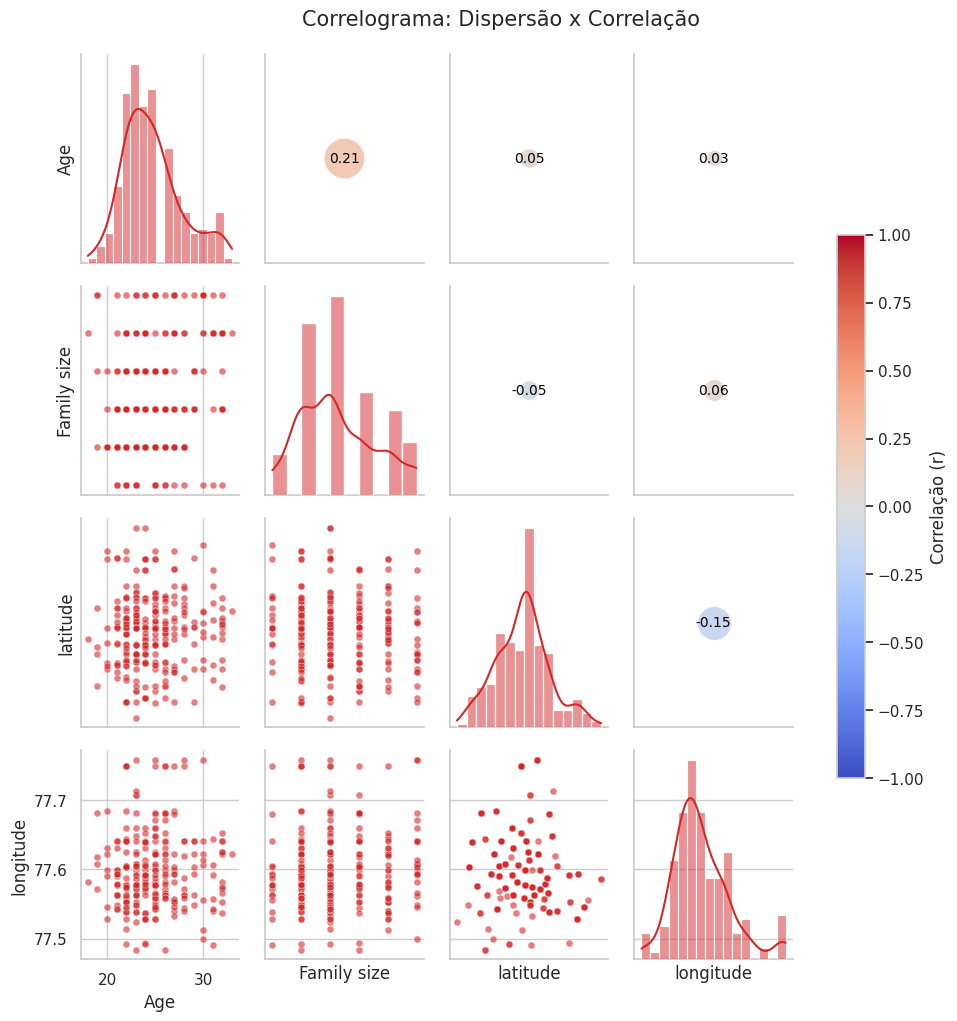

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_MULTI], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_ALERTA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_ALERTA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão x Correlação", y=1.02, fontsize=15)

**Pra discutir:** alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis? (Lembrando que `latitude`/`longitude` tendem a se correlacionar por razões puramente geográficas, não substantivas.)

*Resposta*: Não, nenhuma correlação chama atenção como forte. A matriz de Spearman entre Age, Family size, latitude e longitude tem todos os pares abaixo de |r| < 0,2 — bem longe do patamar (|r| > 0,7) que indicaria redundância entre variáveis.

## Síntese

### Principais Conclusões

1. O dataset tinha qualidade pior do que aparentava à primeira vista: nenhum NaN, mas 103 linhas duplicadas (~27%) e uma coluna inteiramente redundante (Unnamed: 13) — removê-las não alterou a forma das distribuições, só a escala.
2. Idade é o fator que mais diferencia quem respondeu Yes de quem respondeu No (24,3 vs 25,9 anos, p<0,001) — a proporção de Yes cai visivelmente a partir dos 25 anos. Gênero, por outro lado, não mostrou nenhuma associação com a resposta.
3. Occupation está associada a Feedback (p=0,011), mas Customer Type não está associada a Output (p=0,864) — frequência de uso sozinha não prevê satisfação, mas o perfil da pessoa (ocupação) sim.
4. O achado Customer Type = New → Family size = 1 sem nenhuma variação (18/18 casos) é o ponto mais chamativo do dataset — tem cheiro de artefato de geração de dados, não de padrão real, e deveria ser tratado com cautela em qualquer modelo futuro.
5. As variáveis quantitativas (Age, Family size) têm correlação fraca entre si e com as coordenadas geográficas — não há sinal de redundância entre elas, e nenhuma associação forte o suficiente pra sugerir causalidade direta sem investigar variáveis de confusão (como já discutido no cruzamento idade x ocupação).

#Uso de IA

Ferramenta utilizada: Claude

Utilizada Para:
- Estruturar o notebook de EDA seguindo o mesmo roteiro apresentado pela professora no dataset Heart Disease (princípios estrutural, distribucional, relacional e tratamento de outliers), adaptado ao dataset Online Food Delivery.
- Escrever o código de cada etapa: estatística descritiva, testes de normalidade (Shapiro-Wilk), detecção de outliers por IQR, testes de comparação de grupos (T-test/Mann-Whitney, ANOVA/Kruskal-Wallis), Qui-Quadrado, avaliação de fairness e correlograma.
- Ajudar a depurar erros de execução (ex.: nome do arquivo divergente entre o CSV baixado e o código de leitura).

Modificações:
- Estrutura e parte do código, testado e validado
- Modifiquei/decidi por conta própria os pontos de interpretação e julgamento — por exemplo, a decisão de manter os outliers de Age (por serem estatisticamente atípicos mas plausíveis no mundo real) foi discutida comigo, mas a resposta final é minha.
- As perguntas de discussão ao longo do notebook foram propositalmente deixadas em aberto para minhas próprias respostas — não usei texto gerado pela IA para preenchê-las.